# Chapitre 4 - Cours 2 : Thrift et Protocol Buffers, numéros de champ et évolution de schéma

Le cours 1 a montré qu'un format sans schéma doit répéter les noms de champs dans chaque
enregistrement. Apache Thrift (né chez Facebook) et Protocol Buffers (protobuf, conçu chez
Google) imposent un **schéma** et remplacent les noms par de petits **numéros de champ**
(field tags). Ce cours construit leurs encodeurs à la main, octet par octet, puis étudie
comment ces numéros organisent l'évolution du schéma. Il couvre la section *Thrift and
Protocol Buffers* et ses sous-sections *Field tags and schema evolution* et *Datatypes
and schema evolution*.

**Plan.**

1. Un schéma, une IDL et du code généré.
2. Les entiers de longueur variable : varint et zigzag.
3. L'enregistrement d'exemple en Thrift et en Protocol Buffers, octet par octet.
4. Numéros de champ et évolution du schéma : ajouter, supprimer, préserver l'inconnu.
5. Changer le type d'un champ.
6. Une matrice de compatibilité testée automatiquement.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.encoding import PbField, PbMessage
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
R = E.EXAMPLE_RECORD
RP = E.to_pb_record(R)          # mêmes données, noms de champs à la mode protobuf

## 1. Un schéma, une IDL et du code généré (section *Thrift and Protocol Buffers*)

Protocol Buffers exige un schéma pour toute donnée encodée. On l'écrit dans un **langage
de définition d'interface** (IDL). Pour l'enregistrement d'exemple :

```thrift
struct Person {
  1: required string       userName,
  2: optional i64          favoriteNumber,
  3: optional list<string> interests
}
```

```protobuf
message Person {
    required string user_name       = 1;
    optional int64  favorite_number = 2;
    repeated string interests       = 3;
}
```

Chaque champ a un **type**, un **nom** et surtout un **numéro** ; les deux IDL marquent
aussi chaque champ comme obligatoire (`required`) ou facultatif (`optional`). Thrift a un
vrai type liste (`list<string>`) ; protobuf indique une liste par le mot-clé `repeated`.
Notre module représente le schéma protobuf par un objet Python (`E.PERSON_PB`, écrit en
syntaxe proto3 où tout champ est facultatif) :

In [2]:
print(E.PERSON_PB.to_proto())

message Person {
    string user_name = 1;
    int64 favorite_number = 2;
    repeated string interests = 3;
}


Un **générateur de code** lit le schéma et produit, pour chaque langage, des classes qui
savent encoder et décoder les enregistrements conformes. L'application manipule ces
classes ; le format binaire lui reste caché. Le langage de schéma est volontairement
pauvre : des champs et des types, sans contraintes de validation sur les valeurs (pas de
« entre 1 et 65 535 » comme en JSON Schema).

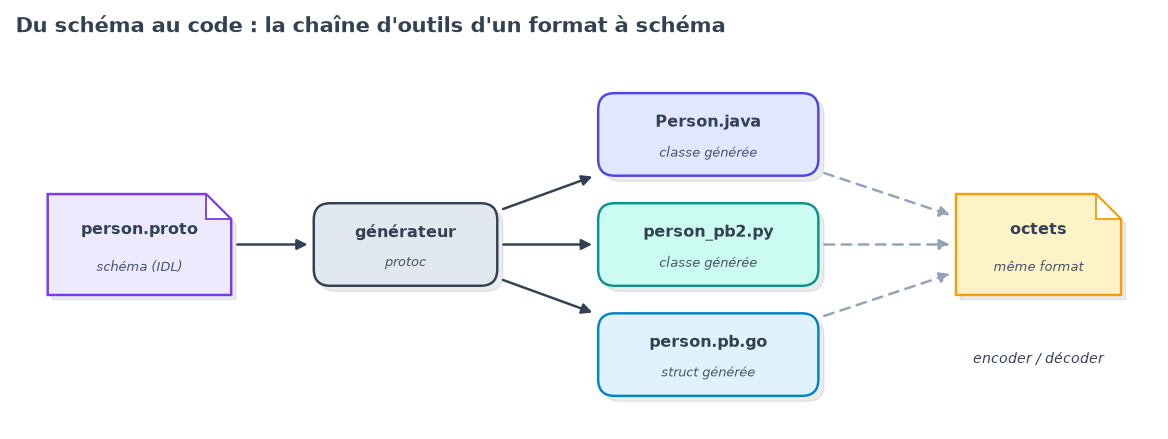

In [3]:
d = Diagram(12.5, 4.0, title="Du schéma au code : la chaîne d'outils d'un format à schéma")
d.box("idl", 1.4, 2.0, "person.proto", sub="schéma (IDL)", color=VIOLET, kind="doc", w=2.0, h=1.1)
d.box("gen", 4.3, 2.0, "générateur", sub="protoc", color=SLATE, w=2.0)
d.box("java", 7.6, 3.2, "Person.java", sub="classe générée", color=INDIGO, w=2.4)
d.box("py", 7.6, 2.0, "person_pb2.py", sub="classe générée", color=TEAL, w=2.4)
d.box("go", 7.6, 0.8, "person.pb.go", sub="struct générée", color=SKY, w=2.4)
d.box("bytes", 11.2, 2.0, "octets", sub="même format", color=AMBER, kind="doc", w=1.8, h=1.1)
d.arrow("idl", "gen")
for k in ("java", "py", "go"):
    d.arrow("gen", k)
    d.arrow(k, "bytes", style="dashed", color=GRAY)
d.note(11.2, 0.75, "encoder / décoder", color=SLATE)
d.show()

> **À retenir.** Thrift et Protocol Buffers décrivent les données par un schéma écrit dans une
> IDL, où chaque champ porte un numéro ; un générateur produit le code d'encodage et de
> décodage pour chaque langage.

## 2. Les entiers de longueur variable : varint et zigzag

Avant d'encoder l'enregistrement, il faut une brique de base : les **varints**. Un entier
est découpé en paquets de 7 bits, du poids faible au poids fort ; chaque paquet occupe un
octet dont le bit de poids fort vaut 1 s'il reste des octets à lire. Un petit nombre
occupe un octet, un grand en occupe jusqu'à dix (pour 64 bits). Exemple : 1337.

In [4]:
v = 1337
b = E.encode_uvarint(v)
print(f"{v} = 0b{v:b}")
print("paquets de 7 bits (poids faible d'abord) :", [f"{(v >> (7 * k)) & 0x7F:07b}" for k in range(2)])
print("octets :", [f"{x:08b}" for x in b], "=", b.hex(" "))
print("décodé :", E.decode_uvarint(b)[0])

1337 = 0b10100111001
paquets de 7 bits (poids faible d'abord) : ['0111001', '0001010']
octets : ['10111001', '00001010'] = b9 0a
décodé : 1337


`0x39` = 0111001 (les 7 bits de poids faible, et un bit de continuation à 1, d'où
`0xb9`), puis `0x0a` = 0001010 (les bits suivants, continuation à 0). La taille vaut
$\max(1, \lceil b/7 \rceil)$ octets pour un entier de $b$ bits.

Problème : les nombres **négatifs**. En complément à deux, $-1$ a ses 64 bits à 1 et son
varint fait 10 octets. D'où le **zigzag** (types `sint32`/`sint64` de protobuf, entiers
de Thrift CompactProtocol et d'Avro) : on entrelace positifs et négatifs,
$0, -1, 1, -2, 2, \dots \mapsto 0, 1, 2, 3, 4, \dots$, c'est-à-dire $z = 2n$ si $n \ge 0$
et $z = -2n - 1$ sinon. Les petits nombres, positifs ou négatifs, restent courts : de
$-64$ à $63$ sur un octet, de $-8\,192$ à $8\,191$ sur deux.

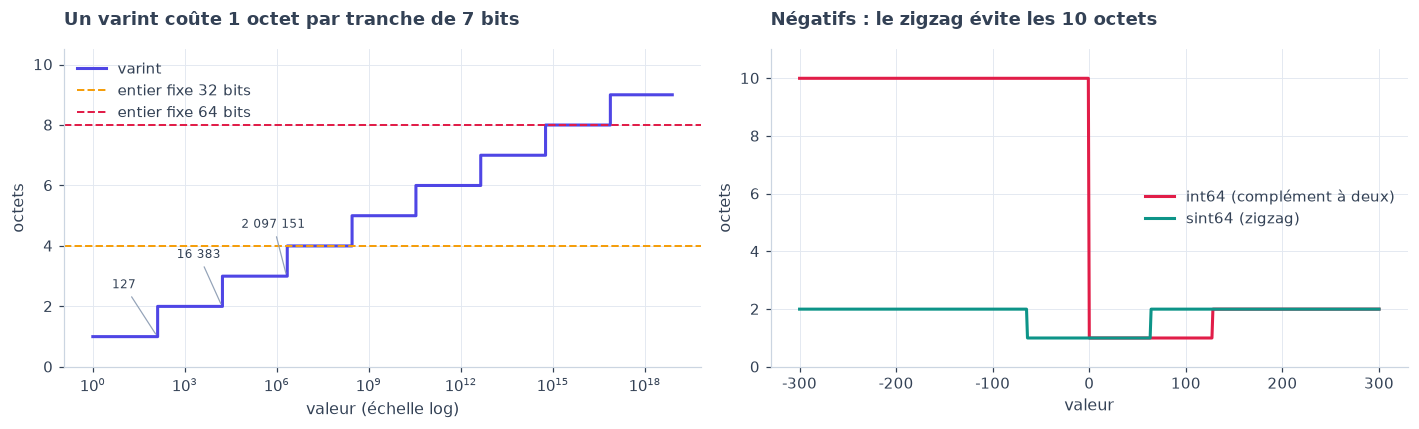

In [5]:
vals = np.unique(np.round(np.logspace(0, 18.9, 600)).astype(np.int64))
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax.step(vals, [E.uvarint_size(int(x)) for x in vals], where="post", color=INDIGO, label="varint")
ax.axhline(4, color=AMBER, ls="--", lw=1.3, label="entier fixe 32 bits")
ax.axhline(8, color=ROSE, ls="--", lw=1.3, label="entier fixe 64 bits")
ax.set_xscale("log"); ax.set_ylim(0, 10.5)
ax.set_xlabel("valeur (échelle log)"); ax.set_ylabel("octets")
ax.set_title("Un varint coûte 1 octet par tranche de 7 bits")
ax.legend(loc="upper left")
for lim, lab in [(127, "127"), (16383, "16 383"), (2 ** 21 - 1, "2 097 151")]:
    ax.annotate(lab, (lim, E.uvarint_size(lim)), (lim / 30, E.uvarint_size(lim) + 1.6), fontsize=8,
                color=SLATE, arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8))

n = np.arange(-300, 301)
ax2.plot(n, [len(E.encode_uvarint(E._twos(int(x)))) for x in n], color=ROSE, label="int64 (complément à deux)")
ax2.plot(n, [len(E.encode_svarint(int(x))) for x in n], color=TEAL, label="sint64 (zigzag)")
ax2.set_xlabel("valeur"); ax2.set_ylabel("octets"); ax2.set_ylim(0, 11)
ax2.set_title("Négatifs : le zigzag évite les 10 octets")
ax2.legend(loc="center right")
plt.tight_layout(); plt.show()

Les varints gagnent tant que les valeurs sont petites, ce qui est le cas typique (compteurs,
âges, tailles, petits écarts). Ils perdent sur des valeurs uniformément grandes : un
hachage de 64 bits prend 10 octets en varint contre 8 en entier fixe (`fixed64`). Mesurons
sur trois distributions réalistes.

In [6]:
dists = {
    "compteurs (géométrique, moy. 20)": rng.geometric(1 / 20, 50_000),
    "identifiants séquentiels (≤ 10 M)": rng.integers(1, 10_000_000, 50_000),
    "horodatages en ms (2018)": rng.integers(1_514_764_800_000, 1_546_300_800_000, 50_000),
    "hachages 64 bits (uniformes)": rng.integers(0, 2 ** 63, 50_000, dtype=np.int64) * 2 + 1,
}
tab = pd.DataFrame({k: {"varint moyen (octets)": np.mean([E.uvarint_size(int(x) & ((1 << 64) - 1)) for x in v]),
                        "fixe 64 bits": 8.0} for k, v in dists.items()}).T
tab["gain du varint"] = (1 - tab["varint moyen (octets)"] / tab["fixe 64 bits"]).map("{:+.0%}".format)
tab.round(2)

,varint moyen (octets),fixe 64 bits,gain du varint
"compteurs (géométrique, moy. 20)",1.00,8.0,+87%
identifiants séquentiels (≤ 10 M),3.79,8.0,+53%
horodatages en ms (2018),6.00,8.0,+25%
hachages 64 bits (uniformes),9.49,8.0,-19%


Des compteurs tiennent en un octet (gain de 87 %), des horodatages en millisecondes en six
(25 %), mais des hachages uniformes coûtent 10 octets au lieu de 8 : protobuf propose
`fixed64` pour ce cas.

> **À retenir.** Un varint code 7 bits utiles par octet : les petits entiers sont très
> compacts, les grands coûtent jusqu'à 10 octets. Le zigzag rend les petits négatifs
> aussi compacts que les petits positifs.

## 3. L'enregistrement d'exemple, octet par octet (section *Thrift and Protocol Buffers*)

Un enregistrement protobuf est la simple concaténation de ses champs. Chaque champ
commence par une **clé** varint qui combine le numéro de champ et un **type d'onde**
(wire type) sur 3 bits : `clé = (numéro << 3) | type_d_onde`. Le type d'onde dit comment
trouver la fin de la valeur : 0 = varint, 1 = 8 octets fixes, 2 = longueur préfixée
(chaînes, octets, messages imbriqués, listes compactées), 5 = 4 octets fixes. Les chaînes
sont en UTF-8, précédées de leur longueur en varint.

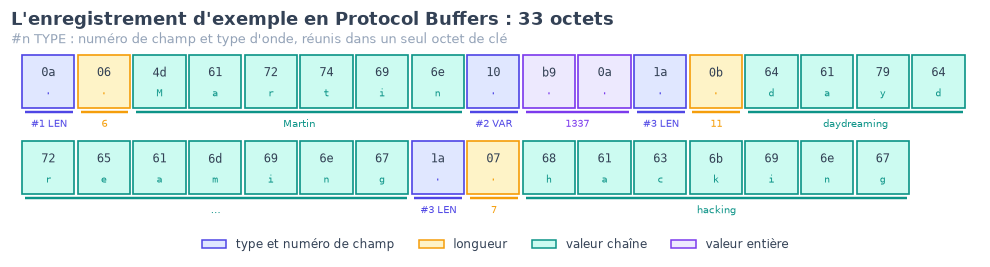

In [7]:
trace = []
pb = E.pb_encode(RP, E.PERSON_PB, trace)
fig = E.draw_byte_map(pb, trace, title=f"L'enregistrement d'exemple en Protocol Buffers : {len(pb)} octets", per_row=17,
                      subtitle_text="#n TYPE : numéro de champ et type d'onde, réunis dans un seul octet de clé")
E.byte_legend(fig.axes[0], ["tag", "length", "str", "int"], loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4)
plt.tight_layout(); plt.show()

In [8]:
cles = []
pos = 0
while pos < len(pb):
    key, p2 = E.decode_uvarint(pb, pos)
    raw, p3 = E._pb_read_raw(pb, p2, key & 7)
    f = E.PERSON_PB.by_tag()[key >> 3]
    cles.append({"position": pos, "octet de clé": f"0x{pb[pos]:02x} = {pb[pos]:08b}", "numéro (clé >> 3)": key >> 3,
                 "type d'onde (clé & 7)": key & 7, "champ": f.name, "octets de valeur": p3 - p2})
    pos = p3
pd.DataFrame(cles)

,position,octet de clé,numéro (clé >> 3),type d'onde (clé & 7),champ,octets de valeur
0,0,0x0a = 00001010,1,2,user_name,7
1,8,0x10 = 00010000,2,0,favorite_number,2
2,11,0x1a = 00011010,3,2,interests,12
3,24,0x1a = 00011010,3,2,interests,8


Les 33 octets se décomposent en 4 clés, 3 longueurs, 26 octets de valeurs (6 + 11 + 7
pour les chaînes, 2 pour le varint de 1337) et... aucun nom de champ. La liste
`interests` n'a pas de type tableau : c'est **le même numéro répété** (clé `0x1a` deux
fois). Comparons avec MessagePack (cours 1) : la moitié des octets ont disparu.

In [9]:
sizes = {"JSON compact": len(E.json_bytes(R)), "MessagePack": len(E.msgpack_encode(R)),
         "Protocol Buffers": len(pb)}
rs = E.role_sizes(trace)
print(sizes)
print("octets par rôle (protobuf) :", {E.ROLES[k]: v for k, v in rs.items()})

{'JSON compact': 81, 'MessagePack': 66, 'Protocol Buffers': 33}
octets par rôle (protobuf) : {'type et numéro de champ': 4, 'longueur': 3, 'valeur chaîne': 24, 'valeur entière': 2}


### Thrift : deux encodages binaires

Thrift propose deux protocoles binaires. **BinaryProtocol** est le plus simple : chaque
champ commence par un octet de type et un numéro de champ sur **2 octets**, les entiers
sont de taille fixe (8 octets pour un `i64`) et les longueurs sur 4 octets ; un octet nul
termine la structure. **CompactProtocol** tasse tout cela : l'écart avec le numéro
précédent et le type tiennent dans un seul octet, entiers et longueurs sont des varints
(zigzag pour les entiers). Il existe aussi un protocole JSON, sans intérêt ici.

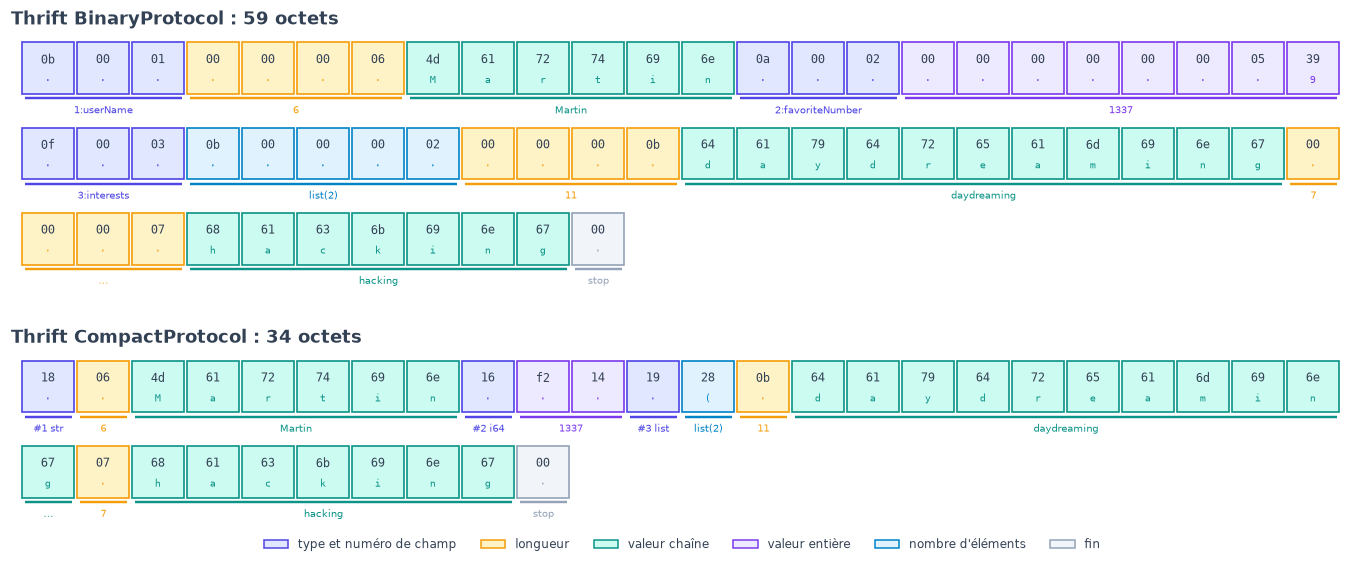

In [10]:
tb, tc = [], []
bin_ = E.thrift_binary_encode(R, trace=tb)
comp = E.thrift_compact_encode(R, trace=tc)
fig, axes = plt.subplots(2, 1, figsize=(12.5, 5.4), gridspec_kw=dict(height_ratios=[3, 2]))
E.draw_byte_map(bin_, tb, title=f"Thrift BinaryProtocol : {len(bin_)} octets", per_row=24, ax=axes[0])
E.draw_byte_map(comp, tc, title=f"Thrift CompactProtocol : {len(comp)} octets", per_row=24, ax=axes[1])
E.byte_legend(axes[1], ["tag", "length", "str", "int", "count", "end"], loc="upper center",
              bbox_to_anchor=(0.5, 0.02), ncol=6)
plt.tight_layout(); plt.show()

BinaryProtocol prend 59 octets : 3 octets par en-tête de champ, 8 pour le seul nombre
1337, 4 par longueur. CompactProtocol descend à 34 octets, un de plus que protobuf (à
cause de l'octet de fin et de l'en-tête de liste) : `0x16` dit « numéro + 1, type
chaîne » (`0x1` dans les 4 bits de poids fort, `0x8` dans ceux de poids faible) et 1337
devient `f2 14` (zigzag : 2 674 en varint).

**Listes de nombres.** Pour une liste d'entiers, répéter la clé devant chaque élément
serait coûteux : proto3 les **compacte** par défaut (packed) en un seul champ de type 2
(une clé, une longueur, puis les varints à la suite). Mesurons sur une liste de 1 000
petits entiers.

In [11]:
sch = PbMessage("Serie", [PbField("valeurs", 1, "sint64", repeated=True)])
serie = [int(x) for x in rng.integers(-60, 60, 1000)]
packed = E.pb_encode({"valeurs": serie}, sch)
unpacked = E.pb_encode({"valeurs": serie}, sch, packed=False)
assert E.pb_decode(packed, sch)["valeurs"] == E.pb_decode(unpacked, sch)["valeurs"] == serie
print(f"compactée : {len(packed)} octets ; une clé par élément : {len(unpacked)} octets ; JSON : {len(E.json_bytes(serie))} octets")

compactée : 1003 octets ; une clé par élément : 2000 octets ; JSON : 3386 octets


Compactée, la liste coûte un octet par élément (plus 3 octets d'en-tête) ; sans
compaction, deux ; en JSON, plus de trois. Les deux formes se décodent de la même
façon, ce qui permet de passer de l'une à l'autre sans casser la compatibilité.

> **À retenir.** Protobuf écrit pour chaque champ une clé (numéro et type d'onde dans un
> varint), puis la valeur, éventuellement précédée de sa longueur. Plus de noms de champs :
> 33 octets au lieu de 66 pour MessagePack. Thrift CompactProtocol fait presque aussi bien (34), BinaryProtocol beaucoup moins (59).

## 4. Numéros de champ et évolution du schéma (section *Field tags and schema evolution*)

Un schéma évolue forcément. Puisqu'un enregistrement encodé n'est qu'une suite de
(numéro, type, valeur), **le numéro est ce qui donne son sens à la donnée**. D'où les
règles :

- **renommer** un champ est sans danger : le nom n'apparaît jamais dans les octets ;
- **changer le numéro** d'un champ est interdit : toutes les données existantes
  deviendraient fausses ;
- **ajouter** un champ est possible avec un **nouveau** numéro.

Pourquoi l'ajout est-il sûr dans les deux sens ? Un ancien lecteur qui rencontre un
numéro inconnu **saute** la valeur : le type d'onde suffit à savoir combien d'octets
passer, sans connaître le champ. C'est la compatibilité ascendante. Un nouveau lecteur qui
lit une ancienne donnée sans le nouveau champ lui donne la **valeur par défaut** du type
(chaîne vide, 0, liste vide) : compatibilité descendante. Vérifions.

In [12]:
PERSON_V2 = PbMessage("Person", E.PERSON_PB.fields + [PbField("photo_url", 4, "string"),
                                                     PbField("age", 5, "int32")])
neuf = {**RP, "photo_url": "https://exemple.org/martin.jpg", "age": 42}
data_v2 = E.pb_encode(neuf, PERSON_V2)
data_v1 = E.pb_encode(RP, E.PERSON_PB)
print("v1 lit une donnée v2 :", E.pb_decode(data_v2, E.PERSON_PB, keep_unknown=False))
print("v2 lit une donnée v1 :", E.pb_decode(data_v1, PERSON_V2))

v1 lit une donnée v2 : {'user_name': 'Martin', 'favorite_number': 1337, 'interests': ['daydreaming', 'hacking']}
v2 lit une donnée v1 : {'user_name': 'Martin', 'favorite_number': 1337, 'interests': ['daydreaming', 'hacking'], 'photo_url': '', 'age': 0}


Pour sauter un champ inconnu, le décodeur n'a besoin que de la clé. Voici ce qu'il fait
pour la donnée v2 lue avec le schéma v1 :

In [13]:
pas = []
pos = 0
connus = E.PERSON_PB.by_tag()
while pos < len(data_v2):
    key, p2 = E.decode_uvarint(data_v2, pos)
    raw, p3 = E._pb_read_raw(data_v2, p2, key & 7)
    tag, wt = key >> 3, key & 7
    regle = {0: "lire un varint", 2: "lire une longueur L, puis L octets", 1: "8 octets", 5: "4 octets"}[wt]
    pas.append({"position": pos, "numéro": tag, "type d'onde": wt, "règle de saut": regle,
                "octets": p3 - pos, "action": f"décoder {connus[tag].name}" if tag in connus else "inconnu : sauter"})
    pos = p3
pd.DataFrame(pas)

,position,numéro,type d'onde,règle de saut,octets,action
0,0,1,2,"lire une longueur L, puis L octets",8,décoder user_name
1,8,2,0,lire un varint,3,décoder favorite_number
2,11,3,2,"lire une longueur L, puis L octets",13,décoder interests
3,24,3,2,"lire une longueur L, puis L octets",9,décoder interests
4,33,4,2,"lire une longueur L, puis L octets",32,inconnu : sauter
5,65,5,0,lire un varint,2,inconnu : sauter


**Supprimer** un champ est l'image miroir de l'ajout : le nouveau lecteur ignore les
anciennes valeurs, l'ancien lecteur reçoit la valeur par défaut. Une règle s'ajoute :
**ne jamais réutiliser** le numéro d'un champ supprimé, car des données anciennes le
contiennent encore quelque part. Que se passe-t-il si on l'oublie ? Supprimons
`favorite_number` (numéro 2) puis, des mois plus tard, réutilisons le numéro 2 pour un
nouveau champ `age`, de même type d'onde.

In [14]:
v3_erreur = PbMessage("Person", [PbField("user_name", 1, "string"), PbField("age", 2, "int32"),
                                 PbField("interests", 3, "string", repeated=True)])
vieux = E.pb_encode({"user_name": "Martin", "favorite_number": 1337, "interests": []}, E.PERSON_PB)
print("donnée de 2017 relue avec le schéma qui réutilise le numéro 2 :", E.pb_decode(vieux, v3_erreur))
v3_correct = PbMessage("Person", [PbField("user_name", 1, "string"), PbField("interests", 3, "string", repeated=True),
                                  PbField("age", 4, "int32")], reserved=[2])
print(v3_correct.to_proto())

donnée de 2017 relue avec le schéma qui réutilise le numéro 2 : {'user_name': 'Martin', 'age': 1337, 'interests': []}
message Person {
    string user_name = 1;
    repeated string interests = 3;
    int32 age = 4;
    reserved 2;
}


Martin aurait 1 337 ans : aucune erreur, juste une donnée fausse, la pire espèce de bogue.
Le mot-clé `reserved` de l'IDL inscrit les numéros retirés dans le schéma pour que
personne ne les réutilise par mégarde.